---
**Обучение и разбор алгоритма KNN на синтетическом датасете и датасете с платформы Kaggle, применение алгоритма ANN на примере поиска похожих слов в русском копусе текста**

---
PDF про KNN (ВШЭ)  
https://github.com/esokolov/ml-minor-hse/blob/master/lectures/lecture14-knn.pdf  

https://github.com/esokolov/ml-minor-hse/blob/master/lectures-2020/lecture02-knn.pdf  

Ноутбук Метрические методы классификации и регрессии (Воронцов)  
https://github.com/andriygav/MachineLearningSeminars/blob/master/sem4/main.ipynb  

Ноутбук от mlcourse.ai  
https://github.com/Yorko/mlcourse.ai/blob/main/jupyter_russian/topic03_decision_trees_knn/topic3_trees_knn.ipynb  

Статья на русском + код  
https://pythonru.com/uroki/sklearn-kmeans-i-knn  
https://gitlab.com/PythonRu/notebooks/-/blob/master/sklearn_kmeans_and_knn.ipynb  

Подробный разбор с кодом на хабре  
https://habr.com/ru/articles/801885/  
https://habr.com/ru/post/680004/

Плейлист по алгоритмам + KNN  
https://www.youtube.com/playlist?list=PLkJJmZ1EJno4H9OfRksHNJgyjXyYcjFtB  
Плейлист по метрикам  
https://www.youtube.com/playlist?list=PLkJJmZ1EJno6CLyvD4DHc32Fed6cPBHje


# Imports

In [ ]:
import math

# пара функций для создания искуственных датасетов
from sklearn.datasets import make_moons
from sklearn.datasets import make_blobs

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

import numpy as np
import matplotlib.pyplot as plt

# темная тема для графиков
plt.style.use('dark_background')

# KNN на синтетическом датасете (классификация)

Создание датасета

In [ ]:
# кол-во классов
CENTERS = 3

# кол-во точек
N_SAMPLES = 60

# создать искусственный датасет точек с координатами x, y
X, y = make_blobs(n_samples=N_SAMPLES, centers=CENTERS, random_state=111)

# рамерности данных
X.shape, y.shape

((60, 2), (60,))

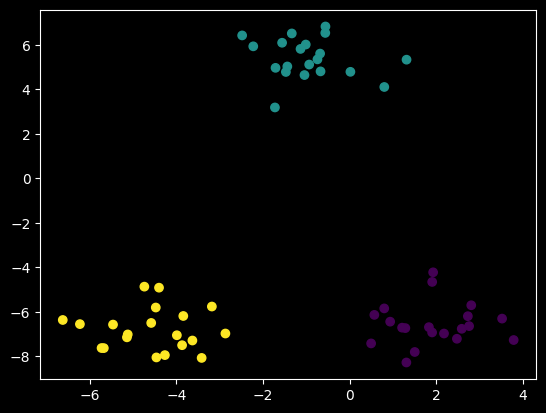

In [ ]:
# отрисовка точек
plt.scatter(X[:, 0], X[:, 1], c=y);

Разделение датасета на тренировочный и тестовый

In [ ]:
from sklearn.model_selection import train_test_split

# разделить данные на тренировочные и тестовые
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=111)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((48, 2), (12, 2), (48,), (12,))

Инициализация модели KNN, обучение, проверка метрики качества на тестовых данных

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# число соседей для алгоритма KNN (гиперпараметр)
N_NEIGHBORDS = 5

# инициализация модели классификации методом ближайших соседей
model = KNeighborsClassifier(n_neighbors=N_NEIGHBORDS)

# обучение модели  (для данного алгоритма просто запоминание обучающей выборки)
model.fit(X_train, y_train)

# проверка качества модели на тестовых данных
# model.score для моделей классификации чаще всего считает метрику accuracy - доля правильных ответов
# model.score для моделей регрессии чаще всего считает R2 score
score = model.score(X_test, y_test)
score

1.0

In [ ]:
# модель просто записывает исходные иксы в атрибут _fit_X
model._fit_X[:5], X_train[:5]

(array([[ 1.21543618, -6.70959116],
        [-4.47718818, -5.80487327],
        [ 0.93983308, -6.44049991],
        [-3.86902792, -7.49716054],
        [-6.62675816, -6.36479175]]),
 array([[ 1.21543618, -6.70959116],
        [-4.47718818, -5.80487327],
        [ 0.93983308, -6.44049991],
        [-3.86902792, -7.49716054],
        [-6.62675816, -6.36479175]]))

In [ ]:
# а игреки в _y
model._y[:5], y_train[:5]

(array([0, 2, 0, 2, 2]), array([0, 2, 0, 2, 2]))

Сделать предсказание моделью

In [ ]:
# и при вызове predict модель считает расстояния и присваивает метки
y_pred = model.predict(X_test)
y_pred

array([1, 0, 0, 1, 2, 0, 1, 0, 1, 1, 1, 2])

Расчет accuracy вручную

In [ ]:
# то что выдала модель надо стравнить с данными датасета чтобы определить насколько точно она предсказала
y_test

array([1, 0, 0, 1, 2, 0, 1, 0, 1, 1, 1, 2])

In [ ]:
# попарное сравнене совпадает ли предсказание модели с реальным правильным ответом
(y_pred == y_test)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

In [ ]:
# model.score - метрика accuracy - доля правильных ответов
np.mean(y_pred == y_test)

1.0

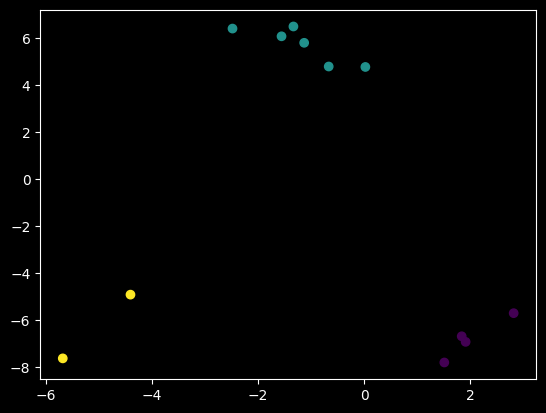

In [ ]:
# отрисока исходных точек и предсказанных моделью их классов
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred);

Отрисовка результатов в помощью mlxtend

In [ ]:
# обновить пакет mlxtend если он выдает ошибку в колабе
# !pip install mlxtend --upgrade --no-deps -q

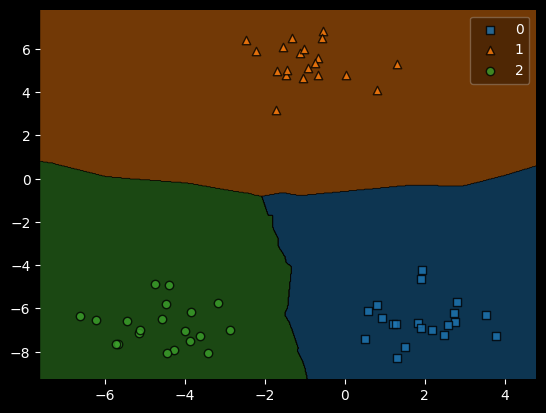

In [ ]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X, y, clf=model);

Сделать предсказание моделью

In [ ]:
# предсказать моделью к какому классу принадлежит новая точка
new_point = [1, 2]

# данные для предсказания должны быть размерности [batch_size, feature_size], поэтому берем в еще одни скобки
predict = model.predict([new_point])
predict

array([1])

# KNN для регрессии

Как работает KNNRegressor:
1. Для каждой точки предсказания находится k ближайших соседей (по X)
2. Предсказание = среднее значение y этих соседей (по Y)
3. При одинаковых расстояниях до нескольких точек (одинаковых X), KNN выбирает первые K из них


Предсказание для X=1: 4.00
5 ближайших соседей для X=1: [2 3 4 5 6]
Среднее значение y у соседей: 4.00


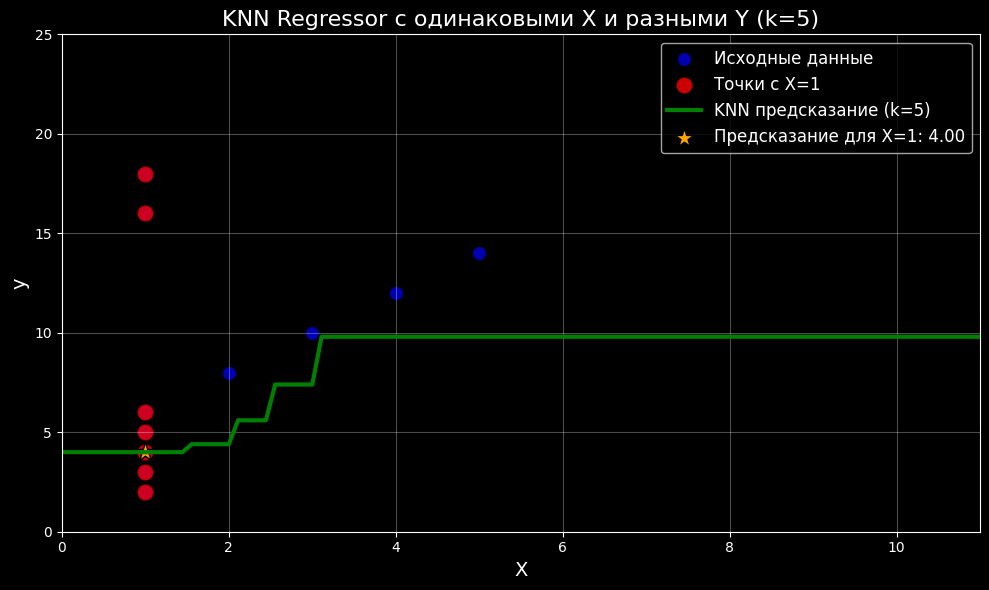

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

# Создаем данные с одинаковыми X но разными Y
np.random.seed(42)
X = np.array([1, 1, 1, 1, 1, 2, 3, 4, 5, 1, 1]).reshape(-1, 1)
y = np.array([2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18])

# Создаем и обучаем модель KNN с 5 соседями
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X, y)

# Создаем точки для предсказания
X_test = np.linspace(0, 11, 100).reshape(-1, 1)
y_pred = knn.predict(X_test)

# Предсказание для точки X=1 (где у нас 5 одинаковых X)
x_special = np.array([[1]])
y_special_pred = knn.predict(x_special)
print(f"\nПредсказание для X=1: {y_special_pred[0]:.2f}")

# Находим 5 ближайших соседей для X=1
distances, indices = knn.kneighbors(x_special)
neighbors_y = y[indices[0]]
print(f"5 ближайших соседей для X=1: {neighbors_y}")
print(f"Среднее значение y у соседей: {np.mean(neighbors_y):.2f}")

# Визуализация
plt.figure(figsize=(10, 6))

# Исходные данные
plt.scatter(X, y, color='blue', s=100, label='Исходные данные', alpha=0.7, edgecolors='black')

# Подсветим точки с X=1
x1_points = X[X.flatten() == 1]
y1_points = y[X.flatten() == 1]
plt.scatter(x1_points, y1_points, color='red', s=150, label='Точки с X=1', alpha=0.8, edgecolors='black')

# Линия предсказаний
plt.plot(X_test, y_pred, color='green', linewidth=3, label='KNN предсказание (k=5)')

# Предсказание для X=1
plt.scatter(x_special, y_special_pred, color='orange', s=200, marker='*',
           label=f'Предсказание для X=1: {y_special_pred[0]:.2f}', edgecolors='black')

# Настройки графика
plt.xlabel('X', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.title('KNN Regressor с одинаковыми X и разными Y (k=5)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.xlim(0, 11)
plt.ylim(0, 25)

plt.tight_layout()
plt.show()


Предсказание для X=1: 4.0
3 ближайших соседа (первые 3 точки с X=1):
Сосед 1: X=1, y=6
Сосед 2: X=1, y=2
Сосед 3: X=1, y=4
Среднее: (6 + 2 + 4)/3 = 4.0


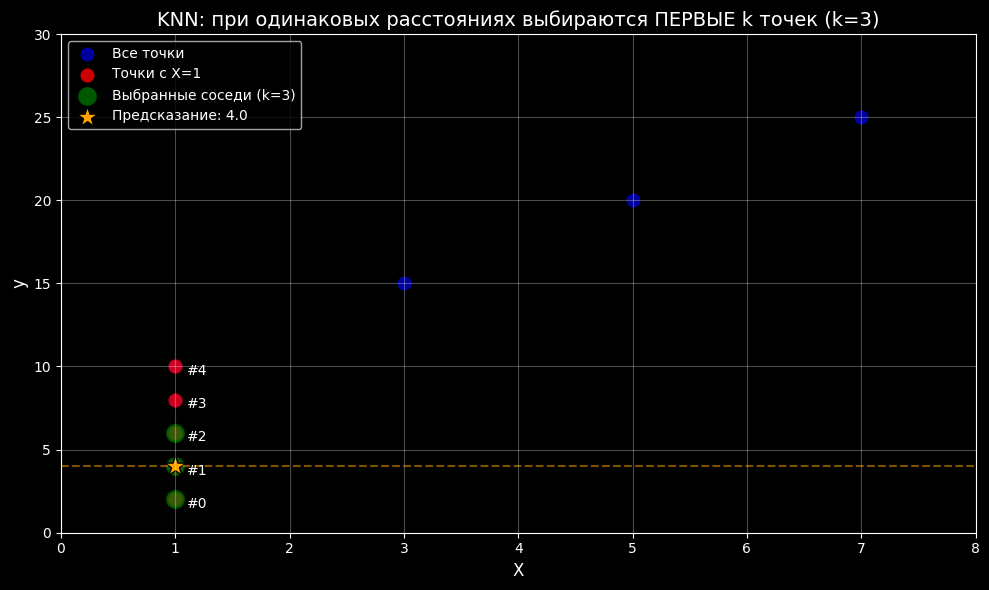

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

# Создаем специальные данные: 5 точек с одинаковым X=1 но разными Y
np.random.seed(42)
X = np.array([1, 1, 1, 1, 1, 3, 5, 7]).reshape(-1, 1)
y = np.array([2, 4, 6, 8, 10, 15, 20, 25])

# Создаем и обучаем KNN с 3 соседями (для наглядности)
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X, y)

# Предсказание для X=1
x_test = np.array([[1]])
y_pred = knn.predict(x_test)[0]

# Находим соседей
distances, indices = knn.kneighbors(x_test)
neighbors_info = [(X[i][0], y[i]) for i in indices[0]]

print(f"\nПредсказание для X=1: {y_pred:.1f}")
print("3 ближайших соседа (первые 3 точки с X=1):")
for i, (x_neighbor, y_neighbor) in enumerate(neighbors_info):
    print(f"Сосед {i+1}: X={x_neighbor}, y={y_neighbor}")

print(f"Среднее: ({neighbors_info[0][1]} + {neighbors_info[1][1]} + {neighbors_info[2][1]})/3 = {y_pred:.1f}")

# Визуализация
plt.figure(figsize=(10, 6))

# Все точки
plt.scatter(X, y, color='blue', s=80, label='Все точки', alpha=0.6)

# Точки с X=1 (подсвечиваем)
x1_mask = X.flatten() == 1
plt.scatter(X[x1_mask], y[x1_mask], color='red', s=120,
           label='Точки с X=1', alpha=0.8, edgecolors='black')

# Выбранные соседи (первые 3)
selected_indices = indices[0][:3]
plt.scatter(X[selected_indices], y[selected_indices], color='green', s=200,
           marker='o', label='Выбранные соседи (k=3)', alpha=0.7, edgecolors='black')

# Предсказание
plt.scatter(x_test, y_pred, color='orange', s=250, marker='*',
           label=f'Предсказание: {y_pred:.1f}', edgecolors='black')

plt.axhline(y=y_pred, color='orange', linestyle='--', alpha=0.5)

# Настройки
plt.xlabel('X', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('KNN: при одинаковых расстояниях выбираются ПЕРВЫЕ k точек (k=3)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 8)
plt.ylim(0, 30)

# Подписи для точек с X=1
for i, (x, y_val) in enumerate(zip(X[x1_mask], y[x1_mask])):
    plt.annotate(f'#{i}', (x + 0.1, y_val - 0.5), fontsize=10)

plt.tight_layout()
plt.show()

# KNN на датасете Kaggle

## Загрузка и чтение датасета

Страница датасета  
https://www.kaggle.com/datasets/sudarshan24byte/online-food-dataset/

In [ ]:
# откатить версию библиотеки kaggle чтобы не было ошибки KeyError: 'username'
!pip install kaggle==1.6.17

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.7/82.7 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for kaggle: filename=kaggle-1.6.17-py3-none-any.whl size=105787 sha256=cd1a2077dc391869231535670bd4012b70a3596deeb9bea6ee7d9a4009da4e71
  Stored in directory: /root/.cache/pip/wheels/ff/55/fb/b27a466be754d2a06ffe0e37b248d844f090a63b51becea85d
Successfully built kaggle
  Attempting uninstall: kaggle
    Found existing installation: kaggle 1.7.4.5
    Uninstalling kaggle-1.7.4.5:
      Successfully uninstalled kaggle-1.7.4.5


In [ ]:
# загрузка датасета
!kaggle datasets download -d sudarshan24byte/online-food-dataset

Dataset URL: https://www.kaggle.com/datasets/sudarshan24byte/online-food-dataset
License(s): MIT
  0% 0.00/3.37k [00:00<?, ?B/s]
100% 3.37k/3.37k [00:00<00:00, 5.85MB/s]


In [ ]:
# распаковка датасета
!unzip online-food-dataset.zip

Archive:  online-food-dataset.zip
  inflating: onlinefoods.csv         


**Описание столбцов**

`Age` - Возраст клиента.  
`Gender` - Пол клиента.  
`Marital Status` - Семейное положение клиента.  
`Occupation` - Должность заказчика.  
`Monthly Income` - Ежемесячный доход клиента.  
`Educational Qualifications` - Образовательные требования заказчика.  
`Family size` - количество человек в семье клиента.  
`latitude` - широта местоположения клиента.  
`longitude` - долгота местоположения клиента.  
`Pin code` - Пин-код местоположения клиента.  
`Output` - текущий статус заказа (например, ожидающий, подтвержденный, доставленный).  
`Feedback` - обратная связь, предоставленная клиентом после получения заказа.

In [ ]:
import pandas as pd

# чтение датасета
df = pd.read_csv('/content/onlinefoods.csv')
df.head(4)

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,latitude,longitude,Pin code,Output,Feedback,Unnamed: 12
0,20,Female,Single,Student,No Income,Post Graduate,4,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,12.9473,77.5616,560019,Yes,Positive,Yes


In [ ]:
# удаление ненужных столбцов
drop_columns = ['latitude', 'longitude', 'Pin code', 'Output', 'Unnamed: 12']
df = df.drop(columns=drop_columns, errors='ignore')

# сделать копию на всякий случай чтобы потом быстро откатится
df_copy = df.copy()

In [ ]:
# показать случайный пример из датасета
df.sample()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Feedback
91,26,Male,Single,Self Employeed,10001 to 25000,Ph.D,1,Positive


In [ ]:
# вывести размерность датасета
df.shape

(388, 8)

In [ ]:
# проверка на пропуски в данных
df.isna().sum()

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Feedback                      0
dtype: int64

In [ ]:
# типы данных
df.dtypes

Age                            int64
Gender                        object
Marital Status                object
Occupation                    object
Monthly Income                object
Educational Qualifications    object
Family size                    int64
Feedback                      object
dtype: object

In [ ]:
# сколько позитивных и негативных отзывов
df['Feedback'].value_counts()

Feedback
Positive     317
Negative      71
Name: count, dtype: int64

## Графики

Гистограмма распределения по возрасту

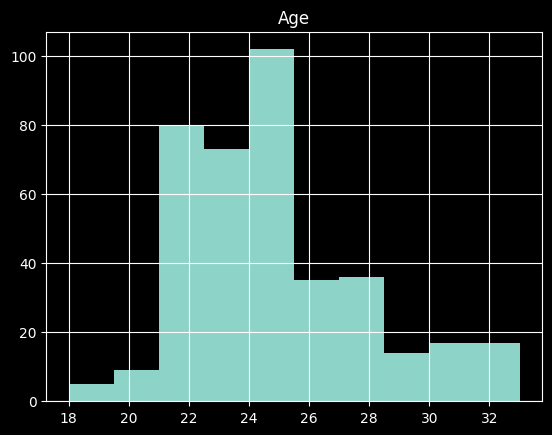

In [ ]:
plt.title('Age')
df['Age'].hist();

Столбчатые диаграммы для нескольких столбцов

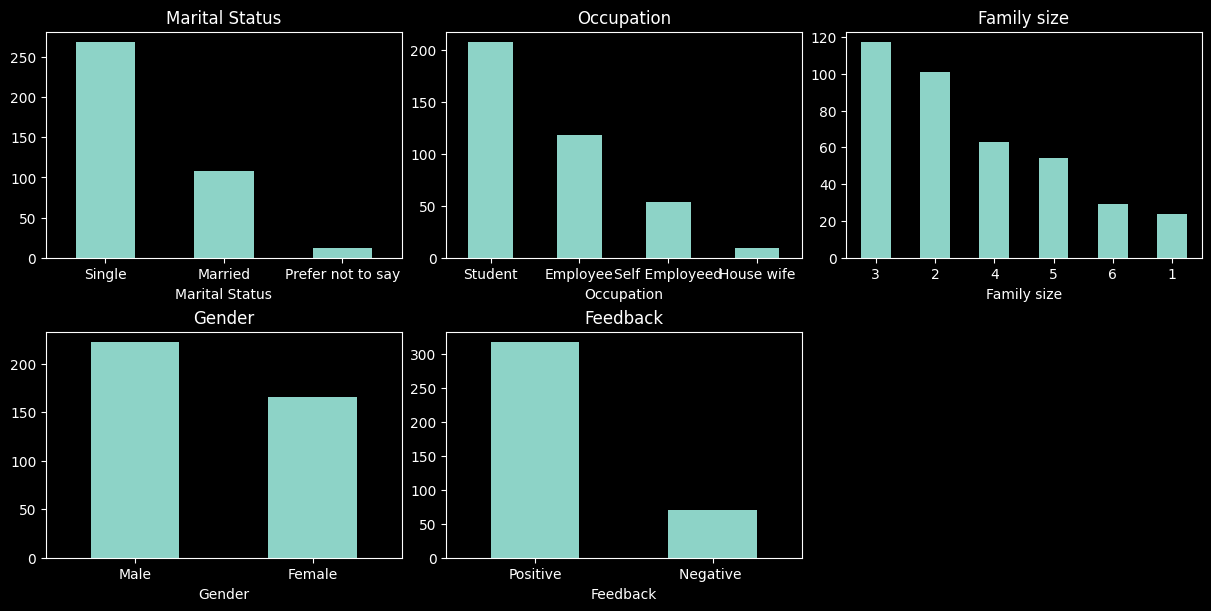

In [ ]:
# названия столбцов датасета
column_names = ['Marital Status', 'Occupation', 'Family size', 'Gender', 'Feedback']

# сколько столбцов и строк будет у нашего большого графика
num_columns = 3
num_rows = math.ceil(len(column_names) / num_columns)

# настройка большого графика
plt.figure(figsize=(12, 6), constrained_layout=True)

# итерация по названиям столбцов датасета и отрисовка столбчатых диаграмм
for i, column_name in enumerate(column_names, start=1):
    ax = plt.subplot(num_rows, num_columns, i)
    ax.set_title(column_name)
    df[column_name].value_counts().plot(kind='bar', ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center')

Столбчатые диаграммы с группировкой столбцов датасета

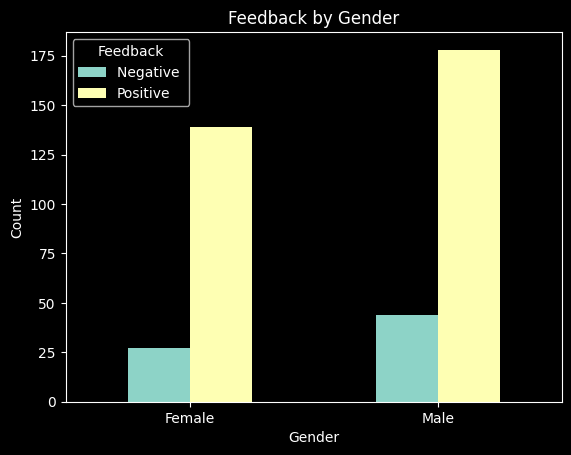

In [ ]:
# отобразить на графике сколько мужчин и женщин оставили негативные и положительные отзывы

# группируем данные по полу и отзыву
column = 'Gender'
target_column = 'Feedback'
grouped = df.groupby([column, target_column]).size().unstack()

# построение столбчатой диаграммы
grouped.plot(kind='bar')  # можно указать stacked=True чтобы было по одному столбцу вместо двух
plt.title(f'{target_column} by {column}')
plt.xlabel(column)
plt.ylabel('Count')
plt.xticks(rotation=0)  # rotation - поворот меток по оси x для лучшей читаемости
plt.legend(title=target_column)
plt.show()

Столбчатые диаграммы с группировкой для нескольких столбцов

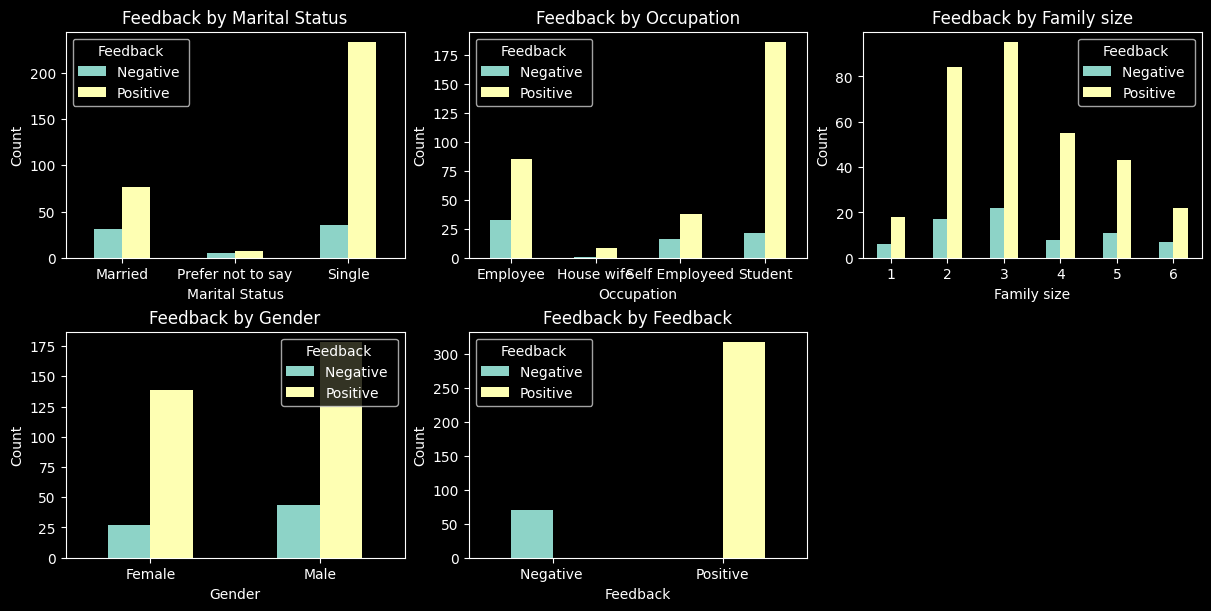

In [ ]:
# тоже самое для нескольких столбцов в цикле

column_names = ['Marital Status', 'Occupation', 'Family size', 'Gender', 'Feedback']

num_columns = 3
num_rows = math.ceil(len(column_names) / num_columns)

plt.figure(figsize=(12, 6), constrained_layout=True)

# название целевого столбца
target_column = 'Feedback'

# итерация по названиям столбцов датасета, их группировка с целевым target_column и отрисовка
for i, curr_column in enumerate(column_names, start=1):
    ax = plt.subplot(num_rows, num_columns, i)
    grouped = df.groupby([curr_column, target_column]).size().unstack()
    grouped.plot(kind='bar', ax=ax)  # stacked=True
    ax.set_title(f'{target_column} by {curr_column}')
    ax.set_xlabel(curr_column)
    ax.set_ylabel('Count')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center')
    ax.legend(title=target_column)

## Кодирование категориальных переменных в числовое представление

In [ ]:
# как видно, у названий могут быть пробелы по краям поэтому будем использовать .strip()
df['Feedback'][:4]

0     Positive
1     Positive
2    Negative 
3     Positive
Name: Feedback, dtype: object

In [ ]:
# кодирование плохих и хороших отзывов к 0 и 1
df['Feedback'] = df['Feedback'].str.strip().map({'Negative' : 0, 'Positive' : 1})
df.sample()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Feedback
14,23,Female,Single,Self Employeed,10001 to 25000,Post Graduate,5,1


Использование LabelEncoder

In [ ]:
from sklearn.preprocessing import LabelEncoder

# столбцы с категориальным типом данных
categirical_columns = ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications']

# словарь в котором будем хранить LabelEncoder для каждогго столбца
encoders = {}
# итерация по названиям столбцов датасета
for column in categirical_columns:
    # инициализация энкодера для текущего столбца и запись в словарь
    encoders[column] = LabelEncoder()
    # кодирование текущего столбца в категориальное представление [0, 1, 2 и тд]
    df[column] = encoders[column].fit_transform(df[column])

In [ ]:
# получившийся словарь для каждого кодированного столбца
encoders

{'Gender': LabelEncoder(),
 'Marital Status': LabelEncoder(),
 'Occupation': LabelEncoder(),
 'Monthly Income': LabelEncoder(),
 'Educational Qualifications': LabelEncoder()}

In [ ]:
# получившийся кодированный столбцец пол
df[['Gender']][:3]

,Gender
0,0
1,0
2,1


In [ ]:
# какие категории были до кодирования
encoders['Gender'].classes_

array(['Female', 'Male'], dtype=object)

In [ ]:
# применить энкодер к новым данным если нужно
# во время настройки энкодера мы использовали fit_transform - поделить на категории и применить кодирование
# во время применения модели на инференсе мы будем использовать transform - применить кодирование
encoders['Gender'].transform(['Male', 'Female'])

array([1, 0])

In [ ]:
# раскодировать обратно значения
encoders['Gender'].inverse_transform([1, 0, 1, 0])

array(['Male', 'Female', 'Male', 'Female'], dtype=object)

In [ ]:
# получившийся датасет
df.head(3)

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Feedback
0,20,0,2,3,4,2,4,1
1,24,0,2,3,2,0,3,1
2,22,1,2,3,2,2,3,0


In [ ]:
# проверить не появились ли пропуски в датасете
df.isna().sum()

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
Feedback                      0
dtype: int64

## Разделение данных для обучения и тестирования модели

In [ ]:
# название столбца который будем предсказывать
# хороший или плохой отзыв оставит клиент в зависимости от его характеристик X
target_column = 'Feedback'

# данные которые будут подаватся на вход модели (характеристики клиента)
X = df.drop(columns=[target_column])
# целевая переменная - какой он оставит отзыв
y = df[target_column]

X.shape, y.shape

((388, 7), (388,))

In [ ]:
# разделить данные на тренировочные и тестовые
# на тренировочных будем обучать модель, на тестовых проверять метрики качества
# преобразовывем массивы из pandas в numpy чтобы потом можно было делать инференс над обычными массивами

X_train, X_test, y_train, y_test = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.2, random_state=111)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((310, 7), (78, 7), (310,), (78,))

## Обучение модели и метрики качества

Инициализация и обучение модели KNN (KNeighborsClassifier - вариант KNN для классификации)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# число соседей для алгоритма KNN (гиперпараметр)
N_NEIGHBORDS = 5

# инициализация модели классификации методом ближайших соседей
model = KNeighborsClassifier(n_neighbors=N_NEIGHBORDS)

# обучение модели (для данного алгоритма просто запоминание обучающей выборки)
model.fit(X_train, y_train);

Расчет метрики качества на тренировочной и тестовой выборках

In [ ]:
# проверка качества модели на тестовых данных
# метод model.score чаще всего расчитывает метрику accuracy для моделей классификации и R2 score для моделей регресии
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print(f'Значение accuracy на тренировочных данных: {train_score:.2f}')
print(f'Значение accuracy на тестовых данных: {test_score:.2f}')

Значение accuracy на тренировочных данных: 0.87
Значение accuracy на тестовых данных: 0.78


Расчет accuracy вручную

In [ ]:
# получение предсказая для тестовых данных (78 отзывов клиентов, предсказанных моделью)
y_pred = model.predict(X_test)
y_pred.shape

(78,)

In [ ]:
# сравнение предсказаний модели с реальными отзывами клиентов y_test - насколько модель точна
accuracy = (y_pred == y_test).sum() / len(y_pred)
accuracy

0.782051282051282

In [ ]:
# тоже самое через mean()
accuracy = (y_pred == y_test).mean()
accuracy

0.782051282051282

Функция `classification_report` подсчитывает метрики `precision` `recall` `f1-score`  
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

In [ ]:
from sklearn.metrics import classification_report

# расчет и вывод метрик
print(classification_report(y_test, y_pred, target_names=['Негативный отзыв', 'Позитивный отзыв']))

                  precision    recall  f1-score   support

Негативный отзыв       0.29      0.14      0.19        14
Позитивный отзыв       0.83      0.92      0.87        64

        accuracy                           0.78        78
       macro avg       0.56      0.53      0.53        78
    weighted avg       0.73      0.78      0.75        78



Перебор гиперпараметра модели - проверить при каком количестве соседей модель показывает наилучший результат по метрике accuracy

In [ ]:
%%time

# будем перебирать например от 1 до 30 соседей
n_neighbors = list(range(1, 30))
# значение метрики обученных моделей складываем в список scores
scores = []

# итерация по кол-вам соседей, инициализируем модель, обучаем, проверяем метрику качества и добавляем в список
for n in n_neighbors:
    model = KNeighborsClassifier(n_neighbors=n)
    model.fit(X_train, y_train)
    score = model.score(X_test, y_test)
    scores.append(score)

CPU times: user 298 ms, sys: 3.99 ms, total: 302 ms
Wall time: 352 ms


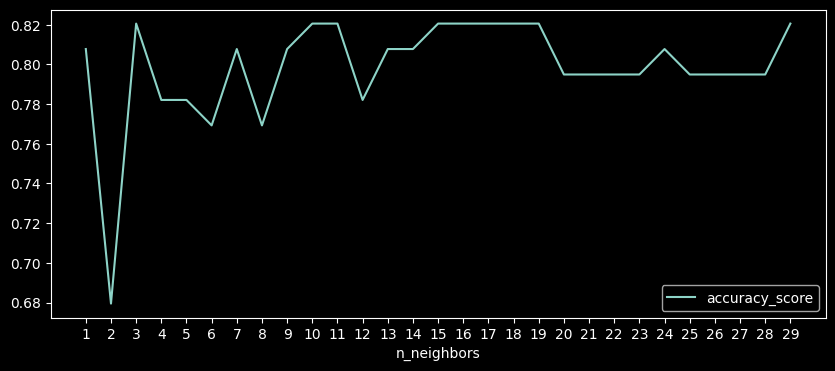

In [ ]:
# отрисовка графика - зависимость метрики от кол-ва соседей
scores_df = pd.DataFrame({'n_neighbors': n_neighbors, 'accuracy_score': scores})
ax = scores_df.plot(x='n_neighbors', y='accuracy_score', figsize=(10, 4))
ax.set_xticks(n_neighbors);

In [ ]:
# при каком кол-ве метрика accuracy максимальна
# в данном примере в обучающей выборке все столбцы категориальные поэтому значения детерменированы
scores_df[scores_df.accuracy_score == scores_df.accuracy_score.max()]

,n_neighbors,accuracy_score
2,3,0.820513
9,10,0.820513
10,11,0.820513
14,15,0.820513
15,16,0.820513
16,17,0.820513
17,18,0.820513
18,19,0.820513
28,29,0.820513


## Получение предсказаний модели на новых входных данных (инференс модели)

In [ ]:
# датасет до кодирования фичей
df_copy.sample()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Feedback
118,32,Female,Married,Employee,25001 to 50000,Graduate,5,Positive


In [ ]:
# датасет после кодирования - на вход модели нужно передать числа в таком формате
X.sample()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size
217,26,1,2,0,0,0,2


In [ ]:
# допустим характеристики новых клиентов имеют вид как в исходном датасете
client1 = [23, 'Male', 'Single', 'Self Employeed', '25001 to 50000', 'Graduate', 4]
client2 = [33, 'Female', 'Married', 'Self Employeed', '25001 to 50000', 'Graduate', 2]

# создать датасет для удобства
df_clients = pd.DataFrame([client1, client2], columns=X.columns)
df_clients

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size
0,23,Male,Single,Self Employeed,25001 to 50000,Graduate,4
1,33,Female,Married,Self Employeed,25001 to 50000,Graduate,2


In [ ]:
# какие столбцы кодировали
categirical_columns

['Gender',
 'Marital Status',
 'Occupation',
 'Monthly Income',
 'Educational Qualifications']

In [ ]:
# энкодеры для каждого столбца
encoders

{'Gender': LabelEncoder(),
 'Marital Status': LabelEncoder(),
 'Occupation': LabelEncoder(),
 'Monthly Income': LabelEncoder(),
 'Educational Qualifications': LabelEncoder()}

In [ ]:
# кодирования столбцов в числа - в тот формат в котором обучали модель
for column in categirical_columns:
    df_clients[column] = encoders[column].transform(df_clients[column])

df_clients

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size
0,23,1,2,2,1,0,4
1,33,0,0,2,1,0,2


In [ ]:
# сделать предикт (инференс) и получить предсказания модели для двух клиентов
y_pred = model.predict(df_clients.to_numpy())
y_pred

array([1, 1])

# ANN

ANN (Approximate Nearest Neighbors) - алгоритмы аппроксимации поиска ближайших соседей  
Примеры алгоритмов - `Annoy` (древовидный поиск), `HNSW` (поиск по графу), `IVF` (поиск по кластерам)

ANN используется для быстрого поиска ближайших соседей в больших наборах данных (например, при поиске похожих картинок, текстов или товаров в больших базах данных)  
В отличие от точного поиска, жертвует небольшой точностью ради значительного ускорения на больших наборах данных .

Различия между ANN и KNN:

Цель:
 - KNN: Используется в задачах классификации или регрессии. Это простой алгоритм, который ищет k ближайших соседей в данных для предсказания метки или значения.
 - ANN: Это подход для быстрого приближенного поиска ближайших соседей в многомерных данных. Используется, когда данных много, а точный поиск (например, с KNN) становится слишком медленным.

Метод поиска:
 - KNN: Выполняет точный поиск ближайших соседей, обычно с использованием евклидова расстояния или других метрик. Это может быть вычислительно дорого для больших наборов данных.
 - ANN: Использует методы приближенного поиска, такие как деревья поиска (KD-Tree, Ball-Tree) или современные структуры, такие как HNSW (Hierarchical Navigable Small World), чтобы ускорить процесс. Этот метод может быть менее точным, но гораздо быстрее.


Установка библиотеки `annoy`  

Документация библиотеки `annoy`  
https://github.com/spotify/annoy

In [ ]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 12.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp310-cp310-linux_x86_64.whl size=552448 sha256=f1b59d60d534754522a57ca052e6ea54a4d03669cd9800813c8ab227a1aa364a
  Stored in directory: /root/.cache/pip/wheels/64/8a/da/f714bcf46c5efdcfcac0559e63370c21abe961c48e3992465a
Successfully built annoy


Импорты

In [ ]:
import numpy as np
import gensim.downloader as api
from annoy import AnnoyIndex

Инициализация модели векторных представлений слов русского корпуса текста

Датасеты и модели Gensim  
https://github.com/piskvorky/gensim-data?tab=readme-ov-file#available-data

Gensim docs  
https://radimrehurek.com/gensim/downloader.html

In [ ]:
# инициализация модели
model = api.load('word2vec-ruscorpora-300')

[==================================================] 100.0% 198.8/198.8MB downloaded


In [ ]:
# атрибуты модели
model.__dict__.keys()

dict_keys(['vector_size', 'index_to_key', 'next_index', 'key_to_index', 'vectors', 'norms', 'expandos', 'mapfile_path', 'lifecycle_events'])

In [ ]:
# [кол-во векторов слов в корпусе текста, размерность каждого вектора]
model.vectors.shape

(184973, 300)

In [ ]:
# более читаемый вывод кол-ва слов в корпусе
f'{model.vectors.shape[0]:_}'

'184_973'

In [ ]:
# первые 10 слов (окончание указывает на часть речи слова)
model.index_to_key[:10]

['весь_DET',
 'человек_NOUN',
 'мочь_VERB',
 'год_NOUN',
 'сказать_VERB',
 'время_NOUN',
 'говорить_VERB',
 'становиться_VERB',
 'знать_VERB',
 'самый_DET']

In [ ]:
# получить вектор слова весь
model.get_vector('весь_DET')

array([-0.01921569, -0.04429   ,  0.01141533,  0.16613917, -0.04715544,
       -0.0196007 , -0.00832584,  0.01355385, -0.06839556,  0.05128639,
        0.01142514,  0.03859952, -0.0283889 ,  0.01141455, -0.01108611,
       -0.0080464 ,  0.02771681,  0.00661864, -0.03316632, -0.01406994,
        0.07541456,  0.06580013, -0.0894529 ,  0.0481694 , -0.02904858,
       -0.0865512 ,  0.0162587 ,  0.03824669,  0.02711524,  0.01763196,
        0.03396021, -0.05100726,  0.06634038, -0.07446305, -0.05505511,
        0.03173188,  0.07907319, -0.02354553,  0.02553871,  0.01147137,
       -0.00437884,  0.01914675,  0.05425941, -0.0924577 ,  0.06919847,
       -0.12068905,  0.02208269, -0.05762626,  0.02164199, -0.14661501,
        0.05885078,  0.01861138,  0.02929406, -0.00935467,  0.10029004,
       -0.04169412, -0.13338292,  0.06460688,  0.02143366, -0.00210405,
       -0.03570003,  0.03872696, -0.07149996, -0.01084066,  0.03955122,
        0.00728331, -0.07691984,  0.03471304, -0.05918778,  0.08

In [ ]:
# ближайшие слова к слову весь (по косинусному расстоянию между векторами)
model.most_similar('весь_DET')

[('замечивать_VERB', 0.47553887963294983),
 ('totem::тотем_NOUN', 0.47478967905044556),
 ('остальной_DET', 0.4544719457626343),
 ('всякий_DET', 0.441199392080307),
 ('равнозначительный_ADJ', 0.42842066287994385),
 ('главное_ADV', 0.4217272996902466),
 ('поломатый_ADJ', 0.41912344098091125),
 ('темна_NOUN', 0.41866740584373474),
 ('разъединый_ADJ', 0.41803601384162903),
 ('многий_DET', 0.4179720878601074)]

Получение всех слов копуса и их векторов

In [ ]:
# получить сами слова
words = np.array(model.index_to_key)

# получить вектор для каждого слова
word_vectors = model.vectors

Обучение индекса ANN

In [ ]:
%%time

# размерность векторов для индекса
vector_size = model.vector_size

# инициализация индекса
index = AnnoyIndex(vector_size, 'euclidean')  # метрика ('angular', 'euclidean')

# добавление векторов в индекс
for i, v in enumerate(word_vectors):
    index.add_item(i, v)

# кол-во деревьев для индекса (гиперпараметр)
n_trees = 10

# строим индекс
index.build(n_trees);

CPU times: user 13.4 s, sys: 212 ms, total: 13.6 s
Wall time: 11.6 s


True

Поиск ближайших соседей в обученном индексе

In [ ]:
# слово, к которому будем искать ближайшие
word = 'человек_NOUN'
# вектор этого слова
word_vector = model.get_vector(word)

# кол-во соседей (сколько ближайших векторов к вектору word_vector хотим найти)
n_neighbors = 5

# поиск ближайших соседей и получение индексов ближайших векторов к вектору word_vector
nearest_neighbors = index.get_nns_by_vector(word_vector, n_neighbors)
nearest_neighbors

[1, 6749, 125743, 2796, 4559]

In [ ]:
# получение самих слов
result_words = [model.index_to_key[index] for index in nearest_neighbors]
result_words

['человек_NOUN',
 'горожанин_NOUN',
 'жора::макинтош_NOUN',
 'преступник_NOUN',
 'обыватель_NOUN']